ПРОЦЕДУРЫ ВКЛЮЧЕНИЯ, ИСКЛЮЧЕНИЯ ПЕРЕМЕННЫХ ИЗ РЕГРЕССИИ.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as sc
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('urozhaynost_usl_own_variance.csv')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      19 non-null     float64
 1   X2      19 non-null     float64
 2   X3      19 non-null     float64
 3   X4      19 non-null     float64
 4   X5      19 non-null     float64
 5   Y       19 non-null     float64
dtypes: float64(6)
memory usage: 1.0 KB


In [4]:
df

,X1,X2,X3,X4,X5,Y
0,1.59,0.26,2.05,0.32,0.14,9.7
1,0.34,0.28,0.46,0.59,0.66,8.4
2,4.63,0.40,6.44,0.43,0.59,9.9
3,2.16,0.26,2.16,0.39,0.16,9.6
4,2.16,0.30,2.69,0.32,0.17,8.6
5,0.68,0.29,0.73,0.42,0.36,12.5
6,0.35,0.26,0.42,0.21,0.08,7.6
7,0.52,0.24,0.49,0.20,0.08,6.9
8,3.42,0.31,3.02,1.37,0.73,13.5
9,1.78,0.30,3.19,0.73,0.17,9.7


## 1.Корреляционный анализ

In [5]:
import seaborn as sns

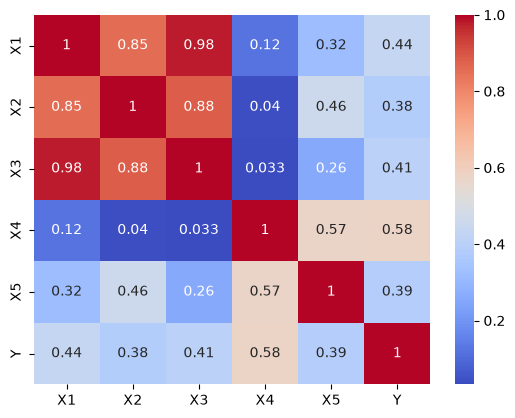

In [6]:
corr_d = df.corr()
sns.heatmap(df.corr(), cmap='coolwarm', annot=True);

In [7]:
def chastnay_corr(rxz, ryz, rxy):
    rxy_z = (rxy - rxz * ryz) / np.sqrt((1 - rxz ** 2) * (1 - ryz**2))
    return rxy_z

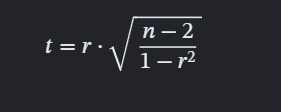
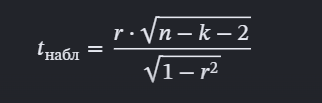

In [8]:
def confidence_parn_coeff(r, n, t_krit):
    try:
        # Считаем t_emp для парной корреляции (df = n - 2)
        t_emp = r * np.sqrt((n - 2) / (1 - r ** 2))
        if abs(t_emp) > abs(t_krit):
            return str(round(r, 2)) + '*'
        else:
            return str(round(r, 2))
    except:
        return "1"

def confidence_chastniy_coeff(r, n, t_krit, k=1):
    try:
        # Для частной корреляции df = n - k - 2
        t_emp = r * np.sqrt((n - k - 2) / (1 - r ** 2))
        if abs(t_emp) > abs(t_krit):
            return str(round(r, 2)) + '*'
        else:
            return str(round(r, 2))
    except:
        return "1"


Матрица парных корреляций ( * - значимый коэффициент)

In [9]:
t_krit_parn = sc.stats.t.ppf(1 - 0.05 / 2, len(df) - 1)
t_krit_chast = sc.stats.t.ppf(1 - 0.05 / 2, len(df) - 3)
n = len(df)
corr_d_parn = corr_d.map(lambda r: confidence_parn_coeff(r, n, t_krit_parn))

In [10]:
corr_d_parn

,X1,X2,X3,X4,X5,Y
X1,1,0.85*,0.98*,0.12,0.32,0.44
X2,0.85*,1,0.88*,0.04,0.46*,0.38
X3,0.98*,0.88*,1,0.03,0.26,0.41
X4,0.12,0.04,0.03,1,0.57*,0.58*
X5,0.32,0.46*,0.26,0.57*,1,0.39
Y,0.44,0.38,0.41,0.58*,0.39,1


In [11]:
for x in corr_d.columns[:-1]:
    max_corr = corr_d[x].drop(x, axis=0)
    x_max_corr = max_corr.drop('Y')
    value, ind = max(x_max_corr), x_max_corr.argmax()
    XX = x_max_corr.index[ind]
    r_chast = chastnay_corr(corr_d[x][XX], corr_d[XX]['Y'], corr_d[x]['Y'])
    znach = confidence_chastniy_coeff(r_chast, n, t_krit_chast, 1)
    print(f'{"--" * 10} {x} {"--" * 10}')
    print(f'Иключаем влияние переменной {XX}')
    print(f'Коэффициент частной корреляции получается: {znach}')

-------------------- X1 --------------------
Иключаем влияние переменной X3
Коэффициент частной корреляции получается: 0.21
-------------------- X2 --------------------
Иключаем влияние переменной X3
Коэффициент частной корреляции получается: 0.06
-------------------- X3 --------------------
Иключаем влияние переменной X1
Коэффициент частной корреляции получается: -0.12
-------------------- X4 --------------------
Иключаем влияние переменной X5
Коэффициент частной корреляции получается: 0.47
-------------------- X5 --------------------
Иключаем влияние переменной X4
Коэффициент частной корреляции получается: 0.09


## 2.Построение регрессионных моделей

In [12]:
import statsmodels.formula.api as sm
from scipy import stats

In [13]:
#Forward future selection
def compare_models(R1, R2, K1, K2, n):
    df1 = K2 - K1          # Степени свободы числителя
    df2 = n - K2 - 1       # Степени свободы знаменателя
    f_krit = stats.f.ppf(1 - 0.05, df1, df2)
    F = ((R2 - R1) / df1) / ((1 - R2) / df2)
    return F > f_krit

spis_regressor = list(df.columns[:-1]) # Приводим к list для удобства drop
curr_regressors = []
start_model = sm.ols('Y ~ 1', df).fit()
n = len(df) # Количество наблюдений

# Сохраняем текущую лучшую модель (изначально это константная модель)
current_best_model = start_model

while True:
    # 1. Проверяем, остались ли еще доступные признаки для добавления
    remaining_features = [f for f in spis_regressor if f not in curr_regressors]
    if not remaining_features:
        print("Все возможные признаки уже добавлены.")
        break
        
    # 2. Ищем признак с максимальной корреляцией среди оставшихся
    idx_for_max_corr = corr_d['Y'].drop(curr_regressors + ['Y']).argmax()
    next_to_add = remaining_features[idx_for_max_corr]
    
    # 3. Формируем новый список регрессоров
    regressors_with_added = curr_regressors + [next_to_add]
    
    # 4. Обучаем новую модель для сравнения
    formula = f"Y ~ {' + '.join(regressors_with_added)}"
    model_for_compare = sm.ols(formula, df).fit()
    
    # 5. Сравниваем модели с помощью функции compare_models
    # K1 и K2 — это количество регрессоров (параметров без константы)
    K1 = len(curr_regressors)
    K2 = len(regressors_with_added)
    
    is_better = compare_models(
        R1=current_best_model.rsquared, 
        R2=model_for_compare.rsquared, 
        K1=K1, 
        K2=K2, 
        n=n
    )
    
    # 6. Условие добавления или остановки цикла
    if is_better:
        curr_regressors.append(next_to_add)
        current_best_model = model_for_compare
        print(f"Добавлен признак: {next_to_add} (R2 улучшился до {model_for_compare.rsquared:.4f})")
    else:
        print(f"Признак {next_to_add} не улучшил модель значимо. Остановка отбора.")
        break

print("\nФинальный набор регрессоров:", curr_regressors)
print(current_best_model.summary())


Добавлен признак: X4 (R2 улучшился до 0.3307)
Признак X1 не улучшил модель значимо. Остановка отбора.

Финальный набор регрессоров: ['X4']
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.331
Model:                            OLS   Adj. R-squared:                  0.291
Method:                 Least Squares   F-statistic:                     8.401
Date:                Thu, 12 Nov 2026   Prob (F-statistic):             0.0100
Time:                        20:56:25   Log-Likelihood:                -36.044
No. Observations:                  19   AIC:                             76.09
Df Residuals:                      17   BIC:                             77.98
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025     

In [14]:
#Backward feature selection
def compare_models(R1, R2, K1, K2, n):
    df1 = K2 - K1          # Степени свободы числителя
    df2 = n - K2 - 1       # Степени свободы знаменателя
    f_krit = stats.f.ppf(1 - 0.05, df1, df2)
    F = ((R2 - R1) / df1) / ((1 - R2) / df2)
    return F > f_krit


# Начинаем со ВСЕХ доступных регрессоров
curr_regressors = list(df.columns[:-1]) 
n = len(df)

# Обучаем стартовую (полную) модель
formula = f"Y ~ {' + '.join(curr_regressors)}"
current_best_model = sm.ols(formula, df).fit()

while True:
    # 1. Если остался всего 1 признак или меньше, удалять больше нечего
    if len(curr_regressors) <= 1:
        print("Достигнут минимальный набор признаков.")
        break
        
    worst_feature = None
    best_candidate_model = None
    max_r2_after_drop = -1 # Ищем модель с наименьшей потерей качества (максимальным R2 среди урезанных)
    
    # 2. Ищем, какой признак "безболезненнее" всего удалить
    for feature in curr_regressors:
        # Формируем тестовый набор БЕЗ одного признака
        test_regressors = [f for f in curr_regressors if f != feature]
        
        # Обучаем уменьшенную модель
        test_formula = f"Y ~ {' + '.join(test_regressors)}"
        test_model = sm.ols(test_formula, df).fit()
        
        # Нам нужен тот признак, после удаления которого R2 останется самым высоким
        if test_model.rsquared > max_r2_after_drop:
            max_r2_after_drop = test_model.rsquared
            worst_feature = feature
            best_candidate_model = test_model

    # 3. Проверяем с помощью F-теста, является ли потеря качества значимой.
    # Сравниваем урезанную модель (best_candidate_model) и полную (current_best_model).
    is_significantly_better = compare_models(
        R1=best_candidate_model.rsquared, 
        R2=current_best_model.rsquared, 
        K1=len(curr_regressors) - 1, 
        K2=len(curr_regressors), 
        n=n
    )
    
    # 4. Условие удаления или остановки
    if not is_significantly_better:
        # Если полная модель НЕ значимо лучше урезанной, значит худший признак бесполезен. 
        # Мы можем спокойно его удалить.
        curr_regressors.remove(worst_feature)
        current_best_model = best_candidate_model
        print(f"Удален признак: {worst_feature:15} | Новый R2: {current_best_model.rsquared:.4f}")
    else:
        # Если полная модель значимо лучше, значит даже самый слабый признак всё еще важен.
        # Удалять его нельзя — останавливаем алгоритм.
        print(f"Признак '{worst_feature}' признан значимым. Остановка удаления.")
        break

print("\nФинальный набор регрессоров (Backward):", curr_regressors)
print(current_best_model.summary())


Удален признак: X1              | Новый R2: 0.4895
Удален признак: X2              | Новый R2: 0.4823
Удален признак: X5              | Новый R2: 0.4803
Признак 'X3' признан значимым. Остановка удаления.

Финальный набор регрессоров (Backward): ['X3', 'X4']
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.480
Model:                            OLS   Adj. R-squared:                  0.415
Method:                 Least Squares   F-statistic:                     7.395
Date:                Thu, 12 Nov 2026   Prob (F-statistic):            0.00532
Time:                        20:56:25   Log-Likelihood:                -33.641
No. Observations:                  19   AIC:                             73.28
Df Residuals:                      16   BIC:                             76.11
Df Model:                           2                                         
Covariance Type:            non

In [15]:
#stepwise feature selection
import statsmodels.api as sm
def stepwise_selection(X, y, threshold_in=0.05, threshold_out=0.10, verbose=True):
    """
    Классический двунаправленный (Stepwise) отбор признаков на основе p-value.
    
    Аргументы:
        X (DataFrame): Набор независимых переменных (предикторов).
        y (Series/array): Целевая переменная.
        threshold_in (float): Порог p-value для добавления переменной (Forward).
        threshold_out (float): Порог p-value для исключения переменной (Backward).
        verbose (bool): Выводить ли логи шагов в консоль.
    """
    included = [] # Список выбранных признаков
    
    while True:
        changed = False
        
        # 1. ШАГ FORWARD: Ищем кандидата на добавление
        excluded = list(set(X.columns) - set(included))
        new_pval = pd.Series(index=excluded, dtype=float)
        
        for new_column in excluded:
            # Обучаем модель с текущими признаками + один новый кандидат
            model = sm.OLS(y, sm.add_constant(X[included + [new_column]])).fit()
            # Записываем p-value этого кандидата
            new_pval[new_column] = model.pvalues[new_column]
            
        best_pval = new_pval.min()
        # Если лучший кандидат значимее, чем наш порог входа (threshold_in)
        if best_pval < threshold_in:
            best_feature = new_pval.idxmin()
            included.append(best_feature)
            changed = True
            if verbose:
                print(f"➕ Добавлен признак: {best_feature:15} (p-value: {best_pval:.4f})")
                
        # 2. ШАГ BACKWARD: Проверяем, не нужно ли кого-то удалить
        if included:
            # Обучаем модель на всех текущих включенных признаках
            model = sm.OLS(y, sm.add_constant(X[included])).fit()
            # Берем p-values всех признаков, кроме константы (intercept)
            pvalues = model.pvalues.iloc[1:] 
            worst_pval = pvalues.max()
            
            # Если самый плохой признак превысил порог выхода (threshold_out)
            if worst_pval > threshold_out:
                worst_feature = pvalues.idxmax()
                included.remove(worst_feature)
                changed = True
                if verbose:
                    print(f"❌ Удален признак:   {worst_feature:15} (p-value: {worst_pval:.4f})")
                    
        # Если за целый цикл мы никого не добавили и не удалили — останавливаемся
        if not changed:
            break
            
    return included

stepwise_selection(df.drop('Y', axis=1), df['Y'])

➕ Добавлен признак: X4              (p-value: 0.0100)
➕ Добавлен признак: X3              (p-value: 0.0475)


['X4', 'X3']

In [16]:
#Гребневая регрессия
import statsmodels.formula.api as sm
model_with_reg = sm.ols(f" Y ~ {'+'.join(df.drop('Y', axis=1).columns)}", df)
results = model_with_reg.fit_regularized(alpha=0.5, L1_wt=0.0)
pd.Series(index=['Intercept'] + list(df.drop('Y', axis=1).columns), data = results.params)

Intercept    4.054840
X1           0.726650
X2           1.041337
X3           0.280071
X4           2.031333
X5           0.922977
dtype: float64

## 3.Факторный анализ

In [114]:
from sklearn.preprocessing import StandardScaler
df = pd.read_csv('urozhaynost_usl_own_variance.csv')

In [115]:
# Стандартизация данных
scaler = StandardScaler()
Z = scaler.fit_transform(df.drop('Y', axis=1))
R = (Z.T @ Z) / len(df)
eig, eival = np.linalg.eigh(R)
eig, eival = eig[::-1], eival[:, ::-1]

In [116]:
A = eival * np.sqrt(eig)

In [117]:
df_A = pd.DataFrame(
    A, 
    index=df.drop('Y', axis=1).columns,               # Строки: имена исходных признаков (X1, X2)
    columns=[f'PC{i+1}' for i in range(A.shape[1])] # Столбцы: PC1, PC2...
)
df_A

,PC1,PC2,PC3,PC4,PC5
X1,-0.949449,0.198302,0.181560,0.145184,-0.071974
X2,-0.938426,0.154559,-0.183583,-0.247799,-0.018983
X3,-0.940938,0.287474,0.145887,0.057392,0.086127
X4,-0.245302,-0.877618,0.403792,-0.081007,0.001721
X5,-0.548968,-0.707752,-0.430670,0.110325,0.008538


In [118]:
F = Z @ A

In [119]:
F = pd.DataFrame(data=F, columns=[f'PC{i+1}' for i in range(A.shape[1])])
F

,PC1,PC2,PC3,PC4,PC5
0,1.234160,0.782267,0.187233,0.094142,0.009764
1,0.263233,-2.064129,-0.892766,0.091477,0.017480
2,-5.891961,0.073525,-0.735232,-0.140682,0.008095
3,0.830626,0.582317,0.286333,0.129058,-0.004833
4,-0.153141,0.930607,0.042872,-0.054191,-0.004604
5,0.785646,-0.414070,-0.442129,-0.060527,-0.003691
6,2.609311,1.013200,-0.013423,-0.031351,-0.003218
7,2.929131,0.996061,0.072977,0.093260,0.001530
8,-3.420824,-3.799931,0.219633,0.034947,-0.010883
9,-0.471711,-0.178646,0.555720,-0.173620,0.026412


In [120]:
from scipy import stats

# 1. Подготовка данных (только признаки X1-X5)
X = df.drop('Y', axis=1)
n = len(X)      # Количество наблюдений (19)
m = X.shape[1]  # Количество признаков (5)

# Корреляционная матрица
R = X.corr().values

# ==========================================
# КРИТЕРИЙ 1: Тест сферичности Бартлетта
# ==========================================
# Определитель корреляционной матрицы
det_R = np.linalg.det(R)

# Статистика Бартлетта
chi2_stat = -(n - 1 - (2 * m + 5) / 6) * np.log(det_R)

# Степени свободы: m * (m - 1) / 2
df_bartlett = m * (m - 1) // 2

# p-value
p_value_bartlett = stats.chi2.sf(chi2_stat, df_bartlett)

print("--- Тест сферичности Бартлетта ---")
print(f"Статистика χ²: {chi2_stat:.4f}")
print(f"Степени свободы (df): {df_bartlett}")
print(f"p-value: {p_value_bartlett:.4e}")
if p_value_bartlett < 0.05:
    print("Вывод: p-value < 0.05. Нулевая гипотеза отвергается. Факторный анализ ПРИМЕНИМ.")
else:
    print("Вывод: p-value >= 0.05. Факторный анализ НЕ применим.")

# ==========================================
# КРИТЕРИЙ 2: Критерий Кайзера (Собственные числа)
# ==========================================
# Собственные значения (eigh возвращает по возрастанию, поэтому переворачиваем [::-1])
eig_vals = np.linalg.eigvalsh(R)[::-1] 

print("\n--- Критерий Кайзера (Собственные значения) ---")
for i, val in enumerate(eig_vals, 1):
    print(f"Компонента {i}: собственное значение λ{i} = {val:.4f}")

# Сколько компонент > 1
n_components_kaiser = np.sum(eig_vals > 1)
print(f"\nКоличество компонент с собственным значением > 1: {n_components_kaiser}")

# Накопленная доля объясненной дисперсии
explained_variance_ratio = eig_vals / np.sum(eig_vals)
cumulative_variance = np.cumsum(explained_variance_ratio)

print(f"\nДоля объясненной дисперсии:")
for i in range(n_components_kaiser):
    print(f"PC{i+1}: {explained_variance_ratio[i]:.2%} (Накопленная: {cumulative_variance[i]:.2%})")

--- Тест сферичности Бартлетта ---
Статистика χ²: 92.5490
Степени свободы (df): 10
p-value: 1.6700e-15
Вывод: p-value < 0.05. Нулевая гипотеза отвергается. Факторный анализ ПРИМЕНИМ.

--- Критерий Кайзера (Собственные значения) ---
Компонента 1: собственное значение λ1 = 3.0290
Компонента 2: собственное значение λ2 = 1.4170
Компонента 3: собственное значение λ3 = 0.4365
Компонента 4: собственное значение λ4 = 0.1045
Компонента 5: собственное значение λ5 = 0.0130

Количество компонент с собственным значением > 1: 2

Доля объясненной дисперсии:
PC1: 60.58% (Накопленная: 60.58%)
PC2: 28.34% (Накопленная: 88.92%)


In [121]:
F['Y'] = df['Y']
F

,PC1,PC2,PC3,PC4,PC5,Y
0,1.234160,0.782267,0.187233,0.094142,0.009764,9.7
1,0.263233,-2.064129,-0.892766,0.091477,0.017480,8.4
2,-5.891961,0.073525,-0.735232,-0.140682,0.008095,9.9
3,0.830626,0.582317,0.286333,0.129058,-0.004833,9.6
4,-0.153141,0.930607,0.042872,-0.054191,-0.004604,8.6
5,0.785646,-0.414070,-0.442129,-0.060527,-0.003691,12.5
6,2.609311,1.013200,-0.013423,-0.031351,-0.003218,7.6
7,2.929131,0.996061,0.072977,0.093260,0.001530,6.9
8,-3.420824,-3.799931,0.219633,0.034947,-0.010883,13.5
9,-0.471711,-0.178646,0.555720,-0.173620,0.026412,9.7


In [122]:
F[['PC1','PC2','Y']]

,PC1,PC2,Y
0,1.234160,0.782267,9.7
1,0.263233,-2.064129,8.4
2,-5.891961,0.073525,9.9
3,0.830626,0.582317,9.6
4,-0.153141,0.930607,8.6
5,0.785646,-0.414070,12.5
6,2.609311,1.013200,7.6
7,2.929131,0.996061,6.9
8,-3.420824,-3.799931,13.5
9,-0.471711,-0.178646,9.7


In [132]:
sm.ols('Y ~ PC1 + PC2', F).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.381
Model:                            OLS   Adj. R-squared:                  0.304
Method:                 Least Squares   F-statistic:                     4.929
Date:                Thu, 12 Nov 2026   Prob (F-statistic):             0.0215
Time:                        22:07:11   Log-Likelihood:                -35.299
No. Observations:                  19   AIC:                             76.60
Df Residuals:                      16   BIC:                             79.43
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      9.5526      0.388     24.636      0.000       8.731      10.375
PC1           -0.3245      0.128     -2.535      0.022      -0.596      -0.053
PC2           -0.5070      0.274     -1.853      0.082      -1.087       0.073
==============================================================================
Omnibus:                        3.806   Durbin-Watson:                   2.280
Prob(Omnibus):                  0.149   Jarque-Bera (JB):                2.251
Skew:                           0.834   Prob(JB):                        0.324
Kurtosis:                       3.243   Cond. No.                         3.03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

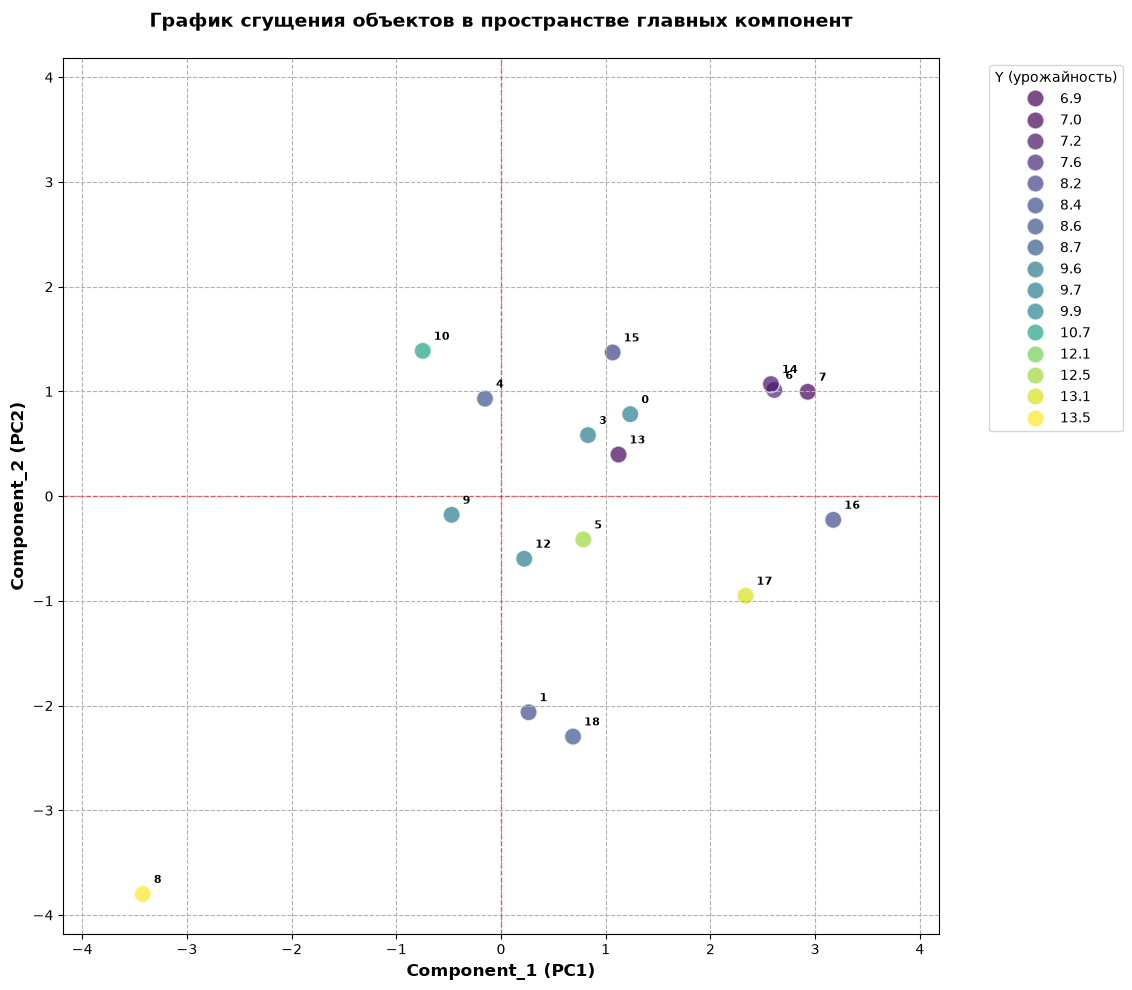

In [131]:
plt.figure(figsize=(12, 10))

scatter = sns.scatterplot(
    x=F['PC1'], 
    y=F['PC2'],
    s=150,
    hue=F['Y'],
    palette='viridis',
    legend='full',
    alpha=0.7
)

# Настройка пределов осей для симметрии
max_val = max(abs(F['PC1'].max()), abs(F['PC2'].min()), 
              abs(F['PC1'].max()), abs(F['PC2'].min()))
margin = max_val * 0.1

plt.xlim(-max_val - margin, max_val + margin)
plt.ylim(-max_val - margin, max_val + margin)

# Подписи точек
for i in range(len(F)):
    plt.annotate(
        f'{i}', 
        (F['PC1'].iloc[i], F['PC2'].iloc[i]),
        textcoords="offset points", 
        xytext=(8, 8),
        fontsize=8,
        fontweight='bold'
    )

plt.xlabel('Component_1 (PC1)', fontsize=12, fontweight='bold')
plt.ylabel('Component_2 (PC2)', fontsize=12, fontweight='bold')
plt.title('График сгущения объектов в пространстве главных компонент\n', fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--')
plt.gca().set_aspect('equal', adjustable='box')
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5, linewidth=1)
plt.axvline(x=0, color='red', linestyle='--', alpha=0.5, linewidth=1)
plt.legend(title='Y (урожайность)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('scatter_pca.png', dpi=400)
plt.show()

--------------------------------------------------------------------------------------

## CLASSWORK

на основании 5 отчетных данный 5 строительных организации получены след результаты Y(Объем) X1(число работников) X2(), матрицу А находим, матрицу F рисуем на плоскости и описывать ..., построить регрессиию по главным компонентам
дз (доделать на +)

In [19]:
df = pd.DataFrame(columns=['X1', 'X2', 'Y'], data=[[3,4,13], [6,5,14], [8,9,16], [2, 8, 12], [7, 6, 15]])

In [20]:
df

,X1,X2,Y
0,3,4,13
1,6,5,14
2,8,9,16
3,2,8,12
4,7,6,15


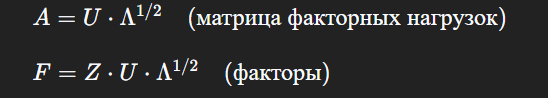

In [21]:
Z = df.drop('Y', axis=1)
Z = Z - Z.mean()
R = (np.transpose(Z) @ Z) / len(df)
eig, eival = np.linalg.eigh(R)

In [22]:
A = eival * np.sqrt(eig)
A

array([[ 0.71462957, -2.20211366],
       [-1.55376236, -1.01282898]])

In [23]:
F = Z @ eival * np.sqrt(eig)
F

,0,1
0,2.156845,7.275440
1,2.746971,-0.343730
2,-2.038819,-8.799274
3,-4.772834,5.426237
4,1.907838,-3.558673


In [24]:
F = F.set_axis(['Component_1', 'Component_2'], axis=1)

In [25]:
F['Y'] = df['Y']
F

,Component_1,Component_2,Y
0,2.156845,7.275440,13
1,2.746971,-0.343730,14
2,-2.038819,-8.799274,16
3,-4.772834,5.426237,12
4,1.907838,-3.558673,15


In [26]:
sm.ols('Y ~ Component_1 + Component_2', F).fit().summary()

C:\Users\Валерий\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\regression\linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.958
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     22.76
Date:                Thu, 12 Nov 2026   Prob (F-statistic):             0.0421
Time:                        15:54:08   Log-Likelihood:               -0.90744
No. Observations:                   5   AIC:                             7.815
Df Residuals:                       2   BIC:                             6.643
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      14.0000      0.205     68.243      0.000      13.117      14.883
Component_1     0.1220      0.070      1.740      0.224      -0.180       0.424
Component_2    -0.2276      0.035     -6.519      0.023      -0.378      -0.077
==============================================================================
Omnibus:                          nan   Durbin-Watson:                   3.060
Prob(Omnibus):                    nan   Jarque-Bera (JB):                0.390
Skew:                          -0.011   Prob(JB):                        0.823
Kurtosis:                       1.632   Cond. No.                         5.88
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [27]:
pd.concat((F,df.drop('Y', axis=1)), axis=1)

,Component_1,Component_2,Y,X1,X2
0,2.156845,7.275440,13,3,4
1,2.746971,-0.343730,14,6,5
2,-2.038819,-8.799274,16,8,9
3,-4.772834,5.426237,12,2,8
4,1.907838,-3.558673,15,7,6


## Регрессия по главной компоненте

In [28]:
sm.ols('Y ~ Component_1', F).fit().summary()

C:\Users\Валерий\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\regression\linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                 -0.248
Method:                 Least Squares   F-statistic:                    0.2040
Date:                Thu, 12 Nov 2026   Prob (F-statistic):              0.682
Time:                        15:54:08   Log-Likelihood:                -8.6631
No. Observations:                   5   AIC:                             21.33
Df Residuals:                       3   BIC:                             20.55
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      14.0000      0.790     17.720      0.000      11.486      16.514
Component_1     0.1220      0.270      0.452      0.682      -0.738       0.982
==============================================================================
Omnibus:                          nan   Durbin-Watson:                   2.751
Prob(Omnibus):                    nan   Jarque-Bera (JB):                0.517
Skew:                           0.540   Prob(JB):                        0.772
Kurtosis:                       1.854   Cond. No.                         2.92
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

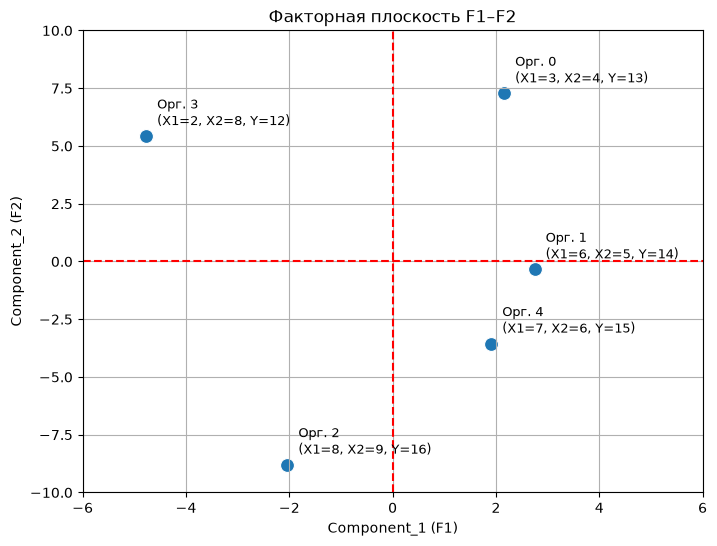

In [29]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=F['Component_1'], y=F['Component_2'], s=100, ax=ax)

# Подписи точек
for i, row in F.iterrows():
    ax.annotate(f'Орг. {i}\n(X1={df.loc[i,"X1"]}, X2={df.loc[i,"X2"]}, Y={df.loc[i,"Y"]})',
                (row['Component_1'], row['Component_2']),
                textcoords="offset points", xytext=(8, 8), fontsize=9)

plt.axhline(y=0, color='red', linewidth=1.5, linestyle='--')
plt.axvline(x=0, color='red', linewidth=1.5, linestyle='--')

plt.grid(True)
plt.xlim(-6, 6)
plt.ylim(-10, 10)
plt.xlabel('Component_1 (F1)')
plt.ylabel('Component_2 (F2)')
plt.title('Факторная плоскость F1–F2')
plt.show()

In [30]:
from IPython.display import display, Markdown, HTML

# Создаем таблицу квадрантов
quadrant_data = {
    'Квадрант': ['I (F1>0, F2>0)', 'II (F1<0, F2>0)', 'III (F1<0, F2<0)', 'IV (F1>0, F2<0)'],
    'Организации': ['Орг. 0', 'Орг. 3', 'Орг. 2', 'Орг. 1, 4'],
    'Смысл': [
        'Большой размер + высокая удельная з.п.',
        'Малый размер + высокая удельная з.п.',
        'Большой размер + низкая удельная з.п.',
        'Средний/большой размер + умеренная з.п.'
    ]
}

quadrant_df = pd.DataFrame(quadrant_data)

# Отображаем таблицу
print("График разделится на 4 квадранта, и станет наглядно видно:\n")
display(quadrant_df)

# Текстовое описание
description = """
**Это упрощает описание сгущений:**

- **Верхний полукруг (F2>0)** — организации с высокой удельной зарплатой и меньшими объёмами работ

- **Нижний полукруг (F2<0)** — организации с большим числом рабочих и большими объёмами

**Нулевые оси делают это разделение визуально очевидным.**
"""

display(Markdown(description))

График разделится на 4 квадранта, и станет наглядно видно:



,Квадрант,Организации,Смысл
0,"I (F1>0, F2>0)",Орг. 0,Большой размер + высокая удельная з.п.
1,"II (F1<0, F2>0)",Орг. 3,Малый размер + высокая удельная з.п.
2,"III (F1<0, F2<0)",Орг. 2,Большой размер + низкая удельная з.п.
3,"IV (F1>0, F2<0)","Орг. 1, 4",Средний/большой размер + умеренная з.п.



**Это упрощает описание сгущений:**

- **Верхний полукруг (F2>0)** — организации с высокой удельной зарплатой и меньшими объёмами работ

- **Нижний полукруг (F2<0)** — организации с большим числом рабочих и большими объёмами

**Нулевые оси делают это разделение визуально очевидным.**
